In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots



In [2]:

df = pd.read_excel("spotify_data_10k.xlsx")
import pandas as pd

pd.set_option('display.max_columns', None)  # يعرض كل الأعمدة
pd.set_option('display.max_colwidth', None)  # يعرض محتوى الكلام جوه الخلية كاملاً

df.head()

,track_id,track_name,artist_name,genre,album_type,release_year,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,explicit,stream_count,in_playlists,language
0,track_00001,Song 1,Queen,NaN,single,1983,18.0,201998.500112,0.651979,0.808438,-1.0,-23.188853,1,0.290543,0.212422,0.505556,0.211911,0.608544,107.080427,4,0.0,7.068590e+07,11.0,Arabic
1,track_00002,Song 2,Bad Bunny,Country,album,2012,66.0,147130.548023,0.549080,0.604588,8.0,-7.528214,1,0.167567,NaN,0.479801,0.545568,0.700135,126.399233,4,0.0,4.229579e+05,16.0,English
2,track_00003,Song 3,Bruno Mars,EDM,album,2023,97.0,186752.376391,0.564957,0.760707,6.0,-10.089849,1,0.289351,0.134327,0.420292,0.179326,0.686540,104.818212,4,0.0,7.989312e+07,13.0,Spanish
3,track_00004,Song 4,BTS,R&B,compilation,2017,82.0,229882.135212,0.883808,0.209222,1.0,-14.091514,0,0.031280,0.066239,0.941878,0.714081,0.722659,131.862504,4,1.0,5.867061e+06,NaN,Spanish
4,track_00005,Song 5,Travis Scott,Pop,single,1996,95.0,193433.264985,0.152025,0.163799,11.0,-24.385553,0,0.520435,0.362427,0.449509,0.658111,0.884495,108.676874,4,1.0,3.288462e+07,8.0,English


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  str    
 1   track_name        10000 non-null  str    
 2   artist_name       9423 non-null   str    
 3   genre             8862 non-null   str    
 4   album_type        9531 non-null   str    
 5   release_year      10000 non-null  int64  
 6   popularity        8946 non-null   float64
 7   duration_ms       10000 non-null  float64
 8   danceability      8901 non-null   float64
 9   energy            9355 non-null   float64
 10  key               8787 non-null   float64
 11  loudness          9199 non-null   float64
 12  mode              10000 non-null  int64  
 13  speechiness       9598 non-null   float64
 14  acousticness      9314 non-null   float64
 15  instrumentalness  10000 non-null  float64
 16  liveness          10000 non-null  float64
 17  valen

# 🎵 Spotify Tracks Data Cleaning & Analytics Project
---
### 📌 Project Pipeline:
1. **Initial Inspection & Duplicates Check**
2. **Missing Values Analysis & Data Types Conversion**
3. **Smart Missing Values Imputation Strategy**
4. **Outliers Detection & Capping/Clipping**
5. **Post-Cleaning Validation**
6. **Feature Engineering**
7. **Exploratory Data Analysis (EDA) - Matplotlib & Seaborn**
8. **Interactive Visualizations & Final Dashboard - Plotly**

## 1. Initial Inspection & Duplicates Check

In [4]:
print(f"إجمالي الأسطر والأعمدة المبدئية: {df.shape}")

duplicate_rows = df.duplicated().sum()
print(f"عدد الصفوف المكررة بالكامل: {duplicate_rows}")


إجمالي الأسطر والأعمدة المبدئية: (10000, 24)
عدد الصفوف المكررة بالكامل: 0


## 2. Missing Values Analysis

In [5]:
df.isnull().sum()

track_id               0
track_name             0
artist_name          577
genre               1138
album_type           469
release_year           0
popularity          1054
duration_ms            0
danceability        1099
energy               645
key                 1213
loudness             801
mode                   0
speechiness          402
acousticness         686
instrumentalness       0
liveness               0
valence                0
tempo                893
time_signature         0
explicit             891
stream_count           0
in_playlists        1133
language             812
dtype: int64

### 3. Categorical Columns Missing Values Imputation
Using a for-loop, we grouped the main categorical columns (`artist_name`, `genre`, `album_type`, `language`) and replaced all missing values with `'Unknown'` to preserve data integrity and avoid altering the true identity of the artworks.

In [6]:
categorical_cols = ['artist_name', 'genre', 'album_type', 'language','explicit']

for col in categorical_cols:
  df[col] = df[col].fillna('Unknown')


In [7]:
print(df[categorical_cols].isnull().sum())

artist_name    0
genre          0
album_type     0
language       0
explicit       0
dtype: int64


### 4. Advanced Numerical Imputation (Groupby Median)
To avoid distorting data distribution or dropping thousands of rows, we imputed missing numerical values using the **Median grouped by Genre**. This ensures that each track receives a realistic statistical value based on its specific musical genre context.

for col in df.select_dtypes(include=['number']).columns:
  #### 1. فل بجروب الفنان الأول
  df[col] = df[col].fillna(
      df.groupby('artist_name')[col].transform('median')
  )

  #### 2. اللي يفضل فاضي يتملي بجروب النوع الموسيقي
  df[col] = df[col].fillna(df.groupby('genre')[col].transform('median'))

  #### 3. الاحتياط الأخير: الميديان العام
  df[col] = df[col].fillna(df[col].median())

In [8]:
for col in df.select_dtypes(include=["number"]).columns:
    df[col] = df[col].fillna(df.groupby("genre")[col].transform("median"))

In [9]:
print(df.select_dtypes(include=['number']).isnull().sum())

release_year        0
popularity          0
duration_ms         0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
stream_count        0
in_playlists        0
dtype: int64


In [10]:
df.describe()

,release_year,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,stream_count,in_playlists
count,10000.000000,10000.000000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,10000.000000
mean,1991.983600,52.186550,2.298537e+05,0.577614,0.522255,5.033300,-17.040989,0.653200,0.359713,0.495223,0.472969,0.496268,0.500204,121.566870,3.949800,2.742023e+08,14.904700
std,18.908884,54.930558,4.675943e+05,0.784343,0.260109,3.500317,37.804646,0.475975,0.191820,0.276094,0.273828,0.259300,0.283209,43.218336,0.381437,5.803713e+09,4.661973
min,1960.000000,0.000000,-9.999900e+04,0.100007,0.050122,-1.000000,-800.000000,0.000000,0.020156,0.000350,0.000178,0.050002,0.010102,0.000000,3.000000,-5.000000e+06,-50.000000
25%,1976.000000,27.000000,1.788551e+05,0.351160,0.309764,2.000000,-22.414023,0.000000,0.196831,0.265010,0.235820,0.272356,0.256211,103.648966,4.000000,1.389214e+07,13.000000
50%,1992.000000,50.000000,2.099845e+05,0.538644,0.521990,5.000000,-15.971085,1.000000,0.360154,0.500688,0.468062,0.494273,0.496562,120.669712,4.000000,3.381432e+07,15.000000
75%,2009.000000,73.000000,2.406954e+05,0.735286,0.742238,8.000000,-9.659422,1.000000,0.519439,0.722875,0.707261,0.718110,0.747954,136.899428,4.000000,6.913722e+07,17.000000
max,2024.000000,999.000000,1.441602e+07,15.500000,0.989883,11.000000,250.000000,1.000000,0.699944,0.989313,0.949921,0.949942,0.989767,999.000000,5.000000,1.500000e+11,35.000000


### 5. Outlier Detection using Interquartile Range (IQR)
To ensure our dataset does not contain extreme anomalous values that could distort future analysis and visualizations, we use the IQR method ($IQR = Q3 - Q1$) to identify potential outliers across all numerical columns.

In [11]:
num_cols = df.select_dtypes(include=["number"]).columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    


In [12]:
outliers

,track_id,track_name,artist_name,genre,album_type,release_year,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,explicit,stream_count,in_playlists,language
7,track_00008,Song 8,Kendrick Lamar,Classical,album,1990,77.0,183796.404086,0.133013,0.572781,5.0,-9.496037,1,0.604057,0.420076,0.234470,0.373078,0.852620,129.481162,4,0.0,1.217262e+08,24.0,English
40,track_00041,Song 41,Imagine Dragons,Pop,album,1985,55.0,206814.875254,0.156048,0.176105,1.0,-15.549368,1,0.489396,0.151154,0.865441,0.298877,0.769452,59.930945,4,0.0,3.117352e+07,-50.0,Portuguese
73,track_00074,Song 74,Unknown,Indie,single,1966,44.0,207138.928905,0.921625,0.465556,8.0,-19.014846,0,0.141391,0.109468,0.662482,0.071981,0.102159,127.493350,4,0.0,3.858437e+06,24.0,Korean
74,track_00075,Song 75,Queen,Unknown,single,1972,57.0,315384.821714,0.671982,0.196945,0.0,-15.636844,0,0.222749,0.690436,0.042121,0.863622,0.139899,66.899189,4,0.0,2.979713e+07,24.0,English
97,track_00098,Song 98,Rihanna,Unknown,single,1993,61.0,138193.025106,0.462524,0.851059,10.0,-16.511796,1,0.298106,0.633961,0.801963,0.796565,0.514981,163.405013,3,0.0,4.472372e+07,28.0,English
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9897,track_09898,Song 9898,Maroon 5,EDM,album,1976,86.0,187204.029948,0.640516,0.503770,0.0,-13.469941,0,0.582847,0.795529,0.576956,0.229050,0.864791,50.486884,4,0.0,5.389701e+07,5.0,Portuguese
9908,track_09909,Song 9909,Billie Eilish,Pop,single,1962,51.0,210298.427843,0.199338,0.258121,1.0,250.000000,0,0.659719,0.257427,0.193222,0.262986,0.868827,106.049471,4,0.0,7.440834e+06,25.0,Arabic
9949,track_09950,Song 9950,Travis Scott,Rock,single,2000,47.0,159201.337023,0.774602,0.848076,2.0,-7.795842,0,0.563681,0.395907,0.804020,0.071394,0.363009,107.094974,4,1.0,7.571425e+07,25.0,Spanish
9992,track_09993,Song 9993,Adele,Unknown,album,1967,40.0,159246.134329,0.382686,0.158261,2.0,-23.243402,0,0.290169,0.769896,0.327678,0.813419,0.491254,119.489857,4,0.0,6.085924e+07,24.0,Unknown


In [13]:
num_cols = df.select_dtypes(include=["number"]).columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    


In [14]:
outliers

,track_id,track_name,artist_name,genre,album_type,release_year,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,explicit,stream_count,in_playlists,language


### 6. Feature Engineering
We create basic, insightful features to enrich our Exploratory Data Analysis (EDA):
1. **duration_min**: Converts track duration from milliseconds to minutes for easier interpretation.
2. **energy_dance_ratio**: Measures the balance between energy and danceability for each track.

In [15]:
df['duration_min'] = (df['duration_ms'] / 60000).round(2)

df['energy_dance_ratio'] = (
    df['energy'] / (df['danceability'] + 0.0001) #Division by Zero Protection
).round(3)

df[[
    'duration_ms',
    'duration_min',
    'energy',
    'danceability',
    'energy_dance_ratio',
]].head()

,duration_ms,duration_min,energy,danceability,energy_dance_ratio
0,201998.500112,3.37,0.808438,0.651979,1.240
1,147130.548023,2.45,0.604588,0.549080,1.101
2,186752.376391,3.11,0.760707,0.564957,1.346
3,229882.135212,3.83,0.209222,0.883808,0.237
4,193433.264985,3.22,0.163799,0.152025,1.077


### 7. Exploratory Data Analysis (EDA) - Track Duration Distribution
Let's visualize the distribution of track lengths (in minutes) using a clean, interactive Histogram and Boxplot to see where most song durations cluster.

### 📊 KPI 1: Total Tracks
Displaying the total number of songs in our Spotify dataset.

In [16]:
total_tracks = df['track_name'].count()

kpi_1 = go.Figure(go.Indicator(
    mode="number",
    value=total_tracks,
    title={"text": "<b>Total Tracks</b>"},
    number={"valueformat": ",", "font": {"color": "#1DB954"}}
))
kpi_1.show()

### 🎤 KPI 2: Total Artists
Calculating the total number of unique artists available in the dataset.

In [17]:
total_artists = df['artist_name'].nunique()

kpi_2 = go.Figure(go.Indicator(
    mode="number",
    value=total_artists,
    title={"text": "<b>Total Artists</b>"},
    number={"valueformat": ",", "font": {"color": "#3b82f6"}}
))
kpi_2.show()

### ⏳ KPI 3: Total Music Hours
Summing up all track durations and converting them into total hours.

In [18]:
total_hours = round(df['duration_min'].sum() / 60, 1)

kpi_3 = go.Figure(
    go.Indicator(
        mode="number",
        value=total_hours,
        title={"text": "<b>Total Music Hours</b>"},
        number={"valueformat": ",", "suffix": " h", "font": {"color": "#f59e0b"}},
    )
)
kpi_3.show()

### ⭐ KPI 4: Average Popularity Score


In [19]:
avg_popularity = round(df['popularity'].mean(), 1)

kpi_4 = go.Figure(
    go.Indicator(
        mode="number",
        value=avg_popularity,
        title={"text": "<b>Average Popularity</b>"},
        number={ "font": {"color": "#ec4899"}},
    )
)

kpi_4.show()

### ⏱️ KPI 5: Average Track Duration
Calculating the average duration for songs in minutes.

In [20]:
avg_duration = round(df['duration_min'].mean(), 2)

kpi_5 = go.Figure(
    go.Indicator(
        mode="number",
        value=avg_duration,
        title={"text": "<b>Avg Track Duration</b>"},
        number={"suffix": " min", "font": {"color": "#8b5cf6"}},
    )
)
kpi_5.show()

### 🎧 KPI 6: Average Streams per Track


In [21]:
avg_streams_m = round(df['stream_count'].mean() / 1e6, 2)

kpi_6 = go.Figure(
    go.Indicator(
        mode="number",
        value=avg_streams_m,
        title={"text": "<b>Avg Streams per Track</b>"},
        number={"valueformat": ",", "suffix": " M", "font": {"color": "#1DB954"}},
    )
)
kpi_6.show()

In [22]:
print(f"{df['stream_count'].mean():,.2f}")

47,158,729.38


### 🌐 KPI 7: Total Streams (In Billions)

Calculating the aggregate stream count across all tracks in billions to capture overall music consumption.

In [23]:
total_streams_b = round(df['stream_count'].sum() / 1e9, 2)

kpi_7 = go.Figure(go.Indicator(
    mode="number",
    value=total_streams_b,
    title={"text": "<b>Total Streams</b>"},
    number={"valueformat": ",", "suffix": " B", "font": {"color": "#10b981"}}
))
kpi_7.show()

### 🎶 KPI 8: Total Genres

Counting the total number of unique music genres available in the dataset.

In [24]:
total_genres = df['genre'].nunique()

kpi_8 = go.Figure(go.Indicator(
    mode="number",
    value=total_genres,
    title={"text": "<b>Total Genres</b>"},
    number={"valueformat": ",", "font": {"color": "#f97316"}}
))
kpi_8.show()

### 🗣️ KPI 9: Total Languages

Calculating the total number of unique languages present in the dataset.

In [25]:
total_languages = df['language'].nunique()

kpi_9 = go.Figure(go.Indicator(
    mode="number",
    value=total_languages,
    title={"text": "<b>Total Languages</b>"},
    number={"valueformat": ",", "font": {"color": "#06b6d4"}}
))
kpi_9.show()

___________________________

### 🔥 Correlation Heatmap
Exploring the statistical correlation between numerical features (Energy, Danceability, Popularity, and Duration) using Seaborn.

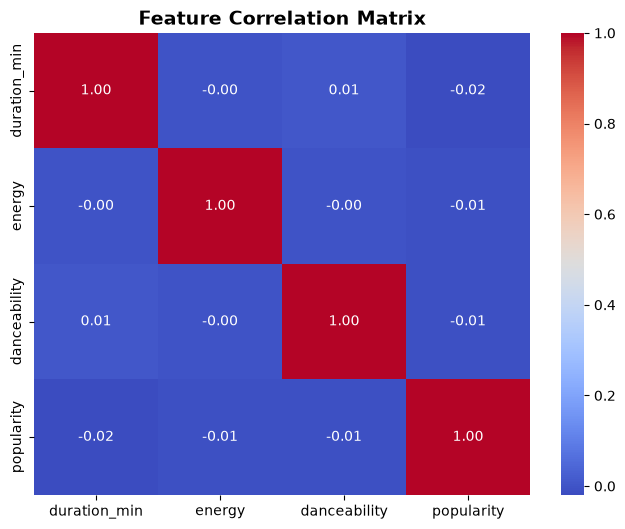

In [26]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df[['duration_min', 'energy', 'danceability', 'popularity']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
)
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.show()

### 📊 Chart 1: Top 10 Artists by Aggregate Streams

**Objective:** Identify the most listened-to artists across the entire dataset by calculating the sum of streams for each artist.

**Key Insight:** 
- **Billie Eilish**, **The Weeknd**, and **BTS** lead the pack, each reaching over **310+ Billion total streams**.
- Using a grouped dataframe (`top_10_artists`) allows us to sort and filter top performers cleanly before visualization.

In [27]:
top_10_artists = df.groupby('artist_name')['stream_count'].sum().reset_index()
top_10_artists = top_10_artists.sort_values(by='stream_count', ascending=True).tail(10)
top_10_artists['streams_in_billions'] = round(top_10_artists['stream_count'] / 1e9, 2)

top_10_artists

,artist_name,stream_count,streams_in_billions
12,Imagine Dragons,1.881074e+10,18.81
18,Post Malone,1.897639e+10,18.98
5,Billie Eilish,1.898934e+10,18.99
17,Maroon 5,1.914222e+10,19.14
20,Rihanna,1.915027e+10,19.15
11,Eminem,1.942871e+10,19.43
6,Bruno Mars,1.975496e+10,19.75
14,Kanye West,2.016468e+10,20.16
13,Justin Bieber,2.192372e+10,21.92
24,Unknown,2.846328e+10,28.46


In [28]:
fig_bar = px.bar(
    top_10_artists,
    x='streams_in_billions',
    y='artist_name',
    title='<b>Top 10 Artists by Total Streams</b>',
    labels={'streams_in_billions': 'Total Streams (Billions B)', 'artist_name': 'Artist Name'},
    color='streams_in_billions',
    color_continuous_scale='Greens'
)
fig_bar.show()

______________________

### 📈 Chart 2: Evolution of Total Streams by Release Year

**Objective:** Examine how listening patterns and overall stream counts evolved over release years.

**Key Insight:** 
- The line chart reveals specific peak years where streaming volumes spiked dramatically.
- Grouping by `release_year` highlights temporal distributions and long-term music catalog consumption.

In [29]:
yearly_streams = df.groupby('release_year')['stream_count'].sum().reset_index()
yearly_streams['streams_in_billions'] = round(yearly_streams['stream_count'] / 1e9, 2)

yearly_streams.head()

,release_year,stream_count,streams_in_billions
0,1960,6.998269e+09,7.00
1,1961,7.883232e+09,7.88
2,1962,6.810815e+09,6.81
3,1963,8.459903e+09,8.46
4,1964,8.024370e+09,8.02


In [30]:
fig_line = px.line(
    yearly_streams,
    x='release_year',
    y='streams_in_billions',
    title='Evolution of Total Streams by Release Year',
    labels={'release_year': 'Release Year', 'streams_in_billions': 'Total Streams (Billions B)'},
    markers=True,
    line_shape='spline',
    template='plotly_white'
)

fig_line.update_traces(line_color='#1DB954', line_width=3, marker=dict(size=6, color='#111827'))
fig_line.update_layout(height=450)

fig_line.show()

_________________

### 🎵 Chart 3: Average Popularity Score by Genre

**Objective:** Compare the performance of different music genres by their average popularity score.

**Key Insight:** 
- Country, Pop, and EDM genres lead with the highest average popularity scores.
- Using groupby normalizes the dataset and provides a clear comparative ranking.

In [31]:
genre_pop = df.groupby('genre')['popularity'].mean().reset_index()
genre_pop = genre_pop.sort_values(by='popularity', ascending=False)

genre_pop

,genre,popularity
0,Classical,52.639319
3,Hip-Hop,50.663575
7,Pop,50.595133
11,Unknown,50.491213
6,Metal,50.208054
8,R&B,50.186813
1,Country,49.548507
2,EDM,49.521154
10,Rock,49.519853
9,Reggaeton,49.220000


C:\Users\gooda\AppData\Local\Temp\ipykernel_18728\1014910946.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  b = sns.barplot(data=genre_pop,x="genre",y="popularity",palette="Purples_r")


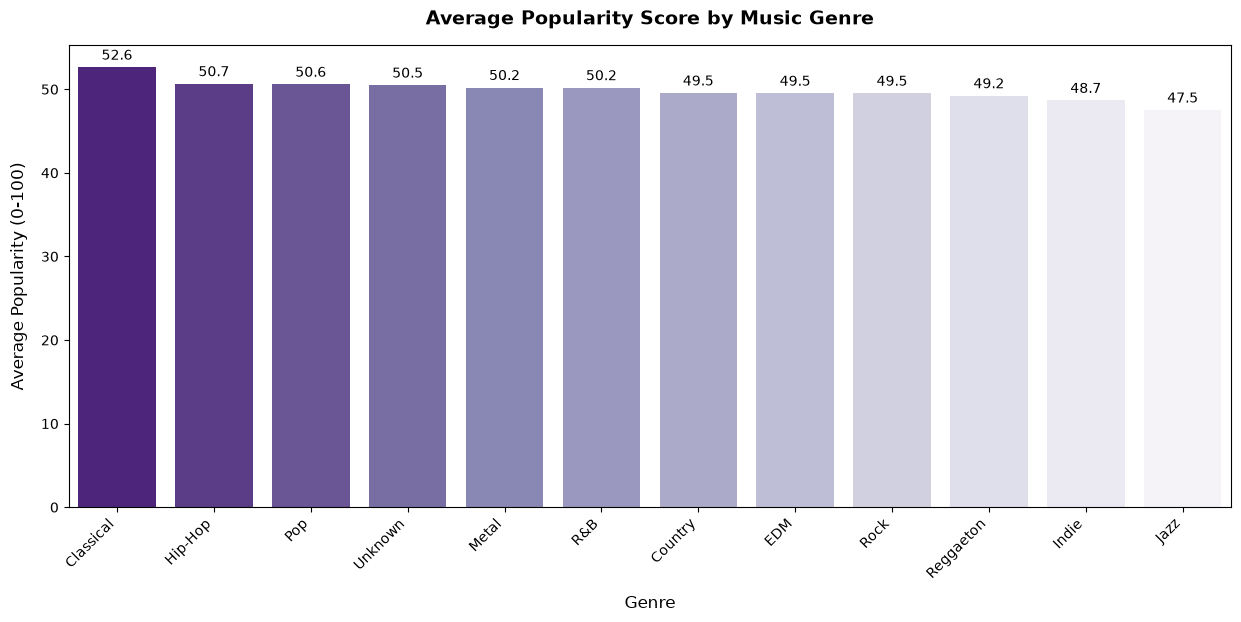

In [32]:
plt.figure(figsize=(15, 6))
b = sns.barplot(data=genre_pop,x="genre",y="popularity",palette="Purples_r")

plt.title('Average Popularity Score by Music Genre', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Genre', fontsize=12, labelpad=10)
plt.ylabel('Average Popularity (0-100)', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')

for i in b.containers:
    plt.bar_label(i,fmt='%.1f',padding=3)
plt.show()

______________

### 🔞 Chart 4: Average Popularity: Clean vs. Explicit Tracks

**Objective:** Compare the average popularity score between explicit and non-explicit tracks.

In [33]:
explicit_comparison = df.groupby('explicit')['popularity'].mean().reset_index()
explicit_comparison['explicit_label'] = explicit_comparison['explicit'].map({0.0: 'Clean', 1.0: 'Explicit'})

explicit_comparison

,explicit,popularity,explicit_label
0,0.0,50.018699,Clean
1,1.0,50.230829,Explicit
2,Unknown,49.840629,NaN


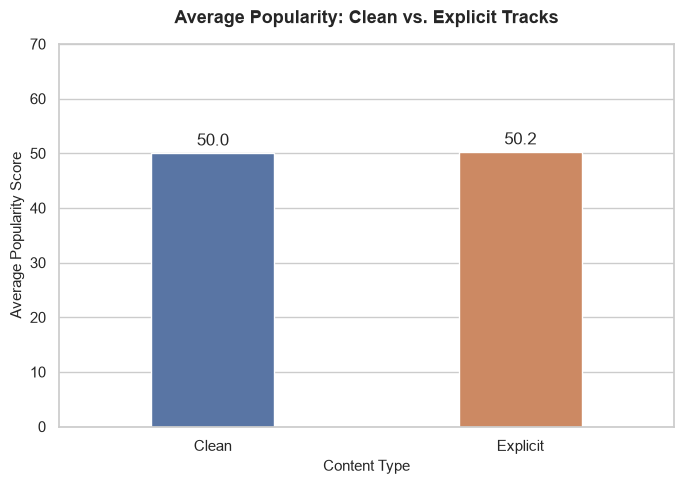

In [34]:
plt.figure(figsize=(7, 5))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=explicit_comparison,
    x='explicit_label',
    y='popularity',
    hue='explicit_label',
    
    legend=False,
    width=0.4
)

plt.title('Average Popularity: Clean vs. Explicit Tracks', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Content Type', fontsize=11)
plt.ylabel('Average Popularity Score', fontsize=11)
plt.ylim(0, 70)

for i in ax.containers:
    plt.bar_label(i, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()

_____________

### 💿 Chart 5: Share of Tracks by Album Type

**Objective:** Analyze the portfolio composition of tracks by album types (Albums, Singles, Compilations).

In [35]:
album_type_df = df.groupby('album_type')['track_id'].count().reset_index()
album_type_df

,album_type,track_id
0,Unknown,469
1,album,4858
2,compilation,1009
3,single,3664


In [36]:
fig_pie = px.pie(
    data_frame=album_type_df, 
    names='album_type', 
    values='track_id', 
    template='plotly_dark', 
    hole=0.6,  
    title="<b>Share of Tracks by Album Type</b>",
    color_discrete_sequence=['#1DB954', '#3b82f6', '#f59e0b', '#8b5cf6']  
)
fig_pie.update_traces(
    textinfo='percent+label', 
    textfont_size=13,
    marker=dict(line=dict(color='#111827', width=2)), 
    pull=[0.05, 0, 0, 0] 
)


fig_pie.update_layout(
    title_x=0.5,
    legend_title='Album Type',
    font=dict(family="Arial", size=12)
)

fig_pie.show()

_______________________________

### 🌍 Chart 6: Total Streams by Song Language

**Objective:** Evaluate which languages generate the highest stream volume globally.

In [37]:
lang_streams = df.groupby('language')['stream_count'].sum().reset_index()
lang_streams['streams_billion'] = round(lang_streams['stream_count'] / 1e9, 2)
lang_streams = lang_streams.sort_values(by='streams_billion', ascending=True)

lang_streams

,language,stream_count,streams_billion
4,Error_Lang,1.345467e+09,1.35
1,???,1.427451e+09,1.43
0,999,2.175400e+09,2.18
7,Japanese,1.297517e+10,12.98
9,Portuguese,1.331624e+10,13.32
6,German,1.627584e+10,16.28
8,Korean,2.163980e+10,21.64
5,French,3.554797e+10,35.55
11,Unknown,4.017800e+10,40.18
2,Arabic,5.085458e+10,50.85


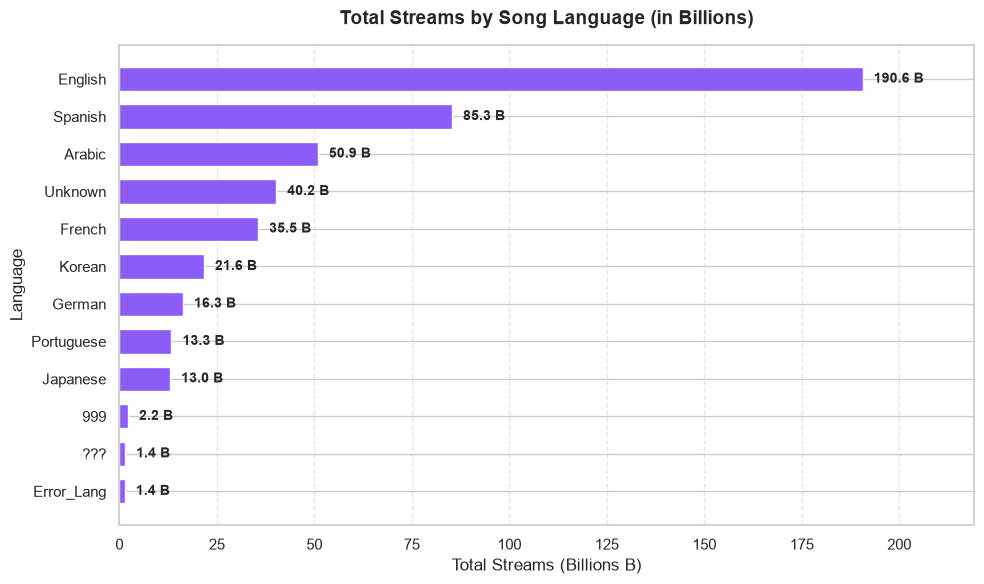

In [38]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    lang_streams['language'],
    lang_streams['streams_billion'],
    color='#8b5cf6',
    height=0.65
)

plt.title('Total Streams by Song Language (in Billions)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Total Streams (Billions B)', fontsize=12)
plt.ylabel('Language', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

max_val = max(lang_streams['streams_billion'])
plt.xlim(0, max_val * 1.15) 

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + (max_val * 0.015), 
        bar.get_y() + bar.get_height() / 2,
        f'{width:,.1f} B',
        ha='left',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()